In [1]:
import math
from dataclasses import dataclass

import numpy as np
import pandas as pd
import seaborn as sns
import sympy as sp
import matplotlib.pyplot as plt


l_x, l_y = 1, 1
T = 2
a = 1

n = 40
m = 40
K = 100

**Вариант 7**

$
\begin{cases}
\dfrac{\partial u}{\partial t} = \dfrac{\partial^2 u}{\partial x^2} + \dfrac{\partial^2 u}{\partial y^2} - xy\sin t, \quad 0 < x < 1,\ 0 < y < 1,\ t > 0, \\
u(0, y, t) = 0, \\
u(1, y, t) = y\cos t, \\
u(x, 0, t) = 0, \\
u(x, 1, t) = x\cos t, \\
u(x, y, 0) = xy,
\end{cases}
\qquad
U(x, y, t) = xy\cos t
$

Задача решается схемами переменных направлений и дробных шагов. Погрешность вычисляем в различные моменты времени, затем исследуем её зависимость от сеточных параметров $\tau$, $h_x$, $h_y$. Каждую схему применяем в двух порядках - сначала дробный шаг по $x$, потом по $y$, и наоборот, - то есть строим два отдельных решения.

Общая постановка - двумерное уравнение параболического типа в прямоугольнике $[0, l_x] \times [0, l_y]$ с граничными условиями первого рода:

$
\dfrac{\partial u}{\partial t} = a\left(\dfrac{\partial^2 u}{\partial x^2} + \dfrac{\partial^2 u}{\partial y^2}\right) + f(x, y, t),
$

$
u(x, 0, t) = \varphi_1(x, t), \qquad u(x, l_y, t) = \varphi_2(x, t), \qquad u(0, y, t) = \varphi_3(y, t), \qquad u(l_x, y, t) = \varphi_4(y, t), \qquad u(x, y, 0) = \psi(x, y).
$

В варианте 7: $a = 1$, $f = -xy\sin t$, $l_x = l_y = 1$, $\varphi_1 = 0$, $\varphi_2 = x\cos t$, $\varphi_3 = 0$, $\varphi_4 = y\cos t$, $\psi = xy$. Время счёта возьмём $T = 2$.

In [2]:
xs, ys, ts = sp.symbols('x y t')

U_sym = xs * ys * sp.cos(ts)
f_sym = -xs * ys * sp.sin(ts)

residual = U_sym.diff(ts) - a * (U_sym.diff(xs, 2) + U_sym.diff(ys, 2)) - f_sym

print('невязка уравнения:', sp.simplify(residual))
print('U(x, 0, t)   =', U_sym.subs(ys, 0))
print('U(x, l_y, t) =', U_sym.subs(ys, l_y))
print('U(0, y, t)   =', U_sym.subs(xs, 0))
print('U(l_x, y, t) =', U_sym.subs(xs, l_x))
print('U(x, y, 0)   =', U_sym.subs(ts, 0))

невязка уравнения: 0
U(x, 0, t)   = 0
U(x, l_y, t) = x*cos(t)
U(0, y, t)   = 0
U(l_x, y, t) = y*cos(t)
U(x, y, 0)   = x*y


In [3]:
u_exact = sp.lambdify((xs, ys, ts), U_sym, 'numpy')
f = sp.lambdify((xs, ys, ts), f_sym, 'numpy')

phi_1 = lambda x, t: 0 * x * t
phi_2 = lambda x, t: x * np.cos(t)
phi_3 = lambda y, t: 0 * y * t
phi_4 = lambda y, t: y * np.cos(t)
psi = lambda x, y: x * y

Аналитическое решение линейно по $x$ и по $y$, поэтому $\dfrac{\partial^2 U}{\partial x^2} = \dfrac{\partial^2 U}{\partial y^2} = 0$. Вторая разностная производная для линейной функции тоже равна нулю:

$
\dfrac{U(x_{i+1}) - 2U(x_i) + U(x_{i-1})}{h^2} = \dfrac{(x_i + h) - 2x_i + (x_i - h)}{h^2}\,y\cos t = 0.
$

Значит, на точном решении аппроксимация пространственных производных не даёт никакой погрешности. Ожидаем, что погрешность численного решения будет определяться шагом по времени и почти не будет зависеть от $h_x$, $h_y$. Это проверим отдельно.

## Конечно-разностная сетка

$
\omega_{h_x h_y}^{\tau} = \{x_i = ih_x,\ i = \overline{0, n};\ y_j = jh_y,\ j = \overline{0, m};\ t^k = k\tau,\ k = \overline{0, K}\}, \qquad h_x = \dfrac{l_x}{n}, \quad h_y = \dfrac{l_y}{m}, \quad \tau = \dfrac{T}{K}.
$

Вторые разностные производные по $x$ и по $y$ обозначим

$
\Lambda_x u_{ij} = \dfrac{u_{i+1,j} - 2u_{ij} + u_{i-1,j}}{h_x^2}, \qquad \Lambda_y u_{ij} = \dfrac{u_{i,j+1} - 2u_{ij} + u_{i,j-1}}{h_y^2}.
$

Погрешность на слое $t^k$: $\varepsilon(t^k) = \max\limits_{i,j} |u_{ij}^k - U(x_i, y_j, t^k)|$, погрешность на всём отрезке времени: $\varepsilon = \max\limits_k \varepsilon(t^k)$.

Решение храним в массиве `u[k, i, j]`: первый индекс - номер слоя по времени, второй - по $x$, третий - по $y$.

In [4]:
@dataclass(frozen=True)
class Grid:
    x: np.ndarray
    y: np.ndarray
    t: np.ndarray
    h_x: float
    h_y: float
    tau: float


def make_grid(n, m, K):
    return Grid(
        x=np.linspace(0, l_x, n + 1),
        y=np.linspace(0, l_y, m + 1),
        t=np.linspace(0, T, K + 1),
        h_x=l_x / n,
        h_y=l_y / m,
        tau=T / K,
    )


@dataclass(frozen=True)
class Result:
    grid: Grid
    u: np.ndarray


def exact_layers(grid):
    return u_exact(grid.x[None, :, None], grid.y[None, None, :], grid.t[:, None, None])


def error(result):
    return np.abs(result.u - exact_layers(result.grid)).max(axis=(1, 2))


def boundary_values(grid, t):
    u = np.zeros((len(grid.x), len(grid.y)))
    u[:, 0] = phi_1(grid.x, t)
    u[:, -1] = phi_2(grid.x, t)
    u[0, :] = phi_3(grid.y, t)
    u[-1, :] = phi_4(grid.y, t)
    return u


def lambda_1(u, h):
    return (u[2:, 1:-1] - 2 * u[1:-1, 1:-1] + u[:-2, 1:-1]) / h**2


def lambda_2(u, h):
    return (u[1:-1, 2:] - 2 * u[1:-1, 1:-1] + u[1:-1, :-2]) / h**2


def second_difference(g, h):
    d = np.zeros_like(g)
    d[1:-1] = (g[2:] - 2 * g[1:-1] + g[:-2]) / h**2
    return d

## Метод прогонки

На каждом дробном шаге обе схемы приводят к трёхдиагональным системам вдоль линий сетки - вдоль $x$ при каждом $j$ или вдоль $y$ при каждом $i$. Все они имеют вид

$
-r\,w_{s-1} + (1 + 2r)\,w_s - r\,w_{s+1} = d_s, \qquad s = \overline{1, N - 1},
$

где $w_0$ и $w_N$ известны из граничных условий. Переносим их в правую часть ($d_1 \mathrel{+}= r w_0$, $d_{N-1} \mathrel{+}= r w_N$) и решаем систему прогонкой:

$
A_s = -\dfrac{c_s}{b_s + a_sA_{s-1}}, \qquad B_s = \dfrac{d_s - a_sB_{s-1}}{b_s + a_sA_{s-1}}, \qquad a_s = c_s = -r, \quad b_s = 1 + 2r,
$

$
w_s = A_sw_{s+1} + B_s, \quad s = N - 1, \ldots, 1 \qquad (w_{N-1} = B_{N-1}).
$

Коэффициенты одинаковы для всех линий, поэтому $A_s$ считаем один раз, а $B_s$ и $w_s$ - сразу для всех линий: в `numpy` это один массив, в котором каждая линия - отдельный столбец. Так за один проход прогонки решаются все $m - 1$ (или $n - 1$) систем.

In [5]:
def tridiagonal_solve(r, d):
    a_s, b_s, c_s = -r, 1 + 2 * r, -r
    N = d.shape[0]
    A, B = np.zeros(N), np.zeros_like(d)

    A[0] = -c_s / b_s
    B[0] = d[0] / b_s

    for s in range(1, N):
        A[s] = -c_s / (b_s + a_s * A[s - 1])
        B[s] = (d[s] - a_s * B[s - 1]) / (b_s + a_s * A[s - 1])

    w = np.zeros_like(d)
    w[-1] = B[-1]

    for s in range(N - 2, -1, -1):
        w[s] = A[s] * w[s + 1] + B[s]

    return w


def solve_lines(r, rhs, first, last):
    d = rhs.copy()
    d[0] += r * first
    d[-1] += r * last
    return tridiagonal_solve(r, d)

Проверим прогонку на случайной системе с несколькими правыми частями:

In [6]:
r_check = 3.0
d_check = np.random.default_rng(0).random((7, 4))
matrix = (np.diag(np.full(7, 1 + 2 * r_check))
          + np.diag(np.full(6, -r_check), 1)
          + np.diag(np.full(6, -r_check), -1))

print('расхождение с np.linalg.solve:', np.abs(tridiagonal_solve(r_check, d_check) - np.linalg.solve(matrix, d_check)).max())

расхождение с np.linalg.solve: 2.7755575615628914e-16


# 1. Метод переменных направлений

Шаг по времени $\tau$ делим на два дробных шага по $\tau/2$. На первом дробном шаге оператор по $x$ аппроксимируется неявно, а по $y$ - явно, на втором - наоборот:

$
\dfrac{u_{ij}^{k+1/2} - u_{ij}^k}{\tau/2} = a\Lambda_x u_{ij}^{k+1/2} + a\Lambda_y u_{ij}^k + f_{ij}^{k+1/2},
$

$
\dfrac{u_{ij}^{k+1} - u_{ij}^{k+1/2}}{\tau/2} = a\Lambda_x u_{ij}^{k+1/2} + a\Lambda_y u_{ij}^{k+1} + f_{ij}^{k+1/2}.
$

В двумерном случае схема абсолютно устойчива и имеет второй порядок по времени: $O(\tau^2 + h_x^2 + h_y^2)$.

Обозначим $r_x = \dfrac{a\tau}{2h_x^2}$, $r_y = \dfrac{a\tau}{2h_y^2}$ и перенесём неизвестные влево. На первом дробном шаге при каждом $j = \overline{1, m - 1}$ получаем систему вдоль $x$:

$
-r_x u_{i-1,j}^{k+1/2} + (1 + 2r_x)\,u_{ij}^{k+1/2} - r_x u_{i+1,j}^{k+1/2} = u_{ij}^k + \dfrac{a\tau}{2}\Lambda_y u_{ij}^k + \dfrac{\tau}{2}f_{ij}^{k+1/2}, \qquad i = \overline{1, n - 1},
$

на втором при каждом $i = \overline{1, n - 1}$ - систему вдоль $y$:

$
-r_y u_{i,j-1}^{k+1} + (1 + 2r_y)\,u_{ij}^{k+1} - r_y u_{i,j+1}^{k+1} = u_{ij}^{k+1/2} + \dfrac{a\tau}{2}\Lambda_x u_{ij}^{k+1/2} + \dfrac{\tau}{2}f_{ij}^{k+1/2}, \qquad j = \overline{1, m - 1}.
$

**Сначала по $y$.** Порядок направлений можно поменять: на первом дробном шаге неявно аппроксимируется оператор по $y$, на втором - по $x$:

$
\dfrac{u_{ij}^{k+1/2} - u_{ij}^k}{\tau/2} = a\Lambda_x u_{ij}^k + a\Lambda_y u_{ij}^{k+1/2} + f_{ij}^{k+1/2},
$

$
\dfrac{u_{ij}^{k+1} - u_{ij}^{k+1/2}}{\tau/2} = a\Lambda_x u_{ij}^{k+1} + a\Lambda_y u_{ij}^{k+1/2} + f_{ij}^{k+1/2}.
$

Системы получаются из записанных выше заменой $x \leftrightarrow y$: на первом дробном шаге прогонки идут вдоль $y$ при каждом $i$, на втором - вдоль $x$ при каждом $j$.

## Граничные значения на промежуточном слое

Прогонкам по $x$ и разности $\Lambda_x u^{k+1/2}$ на втором шаге нужны значения $u_{0j}^{k+1/2}$ и $u_{nj}^{k+1/2}$. Сама схема их не задаёт: промежуточный слой вспомогательный. Значения на сторонах $y = 0$ и $y = l_y$ промежуточного слоя схеме не нужны. Рассмотрим два варианта.

1. **$\varphi(t + \tau/2)$.** Граничные условия выполняются при всех $t$, поэтому берём их значения в момент $t^{k+1/2}$:

$
u_{0j}^{k+1/2} = \varphi_3(y_j, t^{k+1/2}), \qquad u_{nj}^{k+1/2} = \varphi_4(y_j, t^{k+1/2}).
$

2. **Из схемы.** Вычтем второе уравнение схемы из первого:

$
\dfrac{2u_{ij}^{k+1/2} - u_{ij}^k - u_{ij}^{k+1}}{\tau/2} = a\Lambda_y u_{ij}^k - a\Lambda_y u_{ij}^{k+1}
\quad \Longrightarrow \quad
u_{ij}^{k+1/2} = \dfrac{u_{ij}^k + u_{ij}^{k+1}}{2} - \dfrac{a\tau}{4}\Lambda_y\left(u_{ij}^{k+1} - u_{ij}^k\right).
$

Во внутренних узлах промежуточный слой связан с целыми слоями именно так. Запишем это же соотношение и в граничных узлах $i = 0$, $i = n$, где $u^k$ и $u^{k+1}$ известны из граничных условий:

$
u_{0j}^{k+1/2} = \dfrac{\varphi_3(y_j, t^k) + \varphi_3(y_j, t^{k+1})}{2} - \dfrac{a\tau}{4}\Lambda_y\left(\varphi_3(y_j, t^{k+1}) - \varphi_3(y_j, t^k)\right),
$

и так же при $i = n$ с $\varphi_4$.

При порядке «сначала по $y$» промежуточный слой нужен прогонкам по $y$, поэтому значения задаются на сторонах $y = 0$ и $y = l_y$. Формулы те же с заменой $x \leftrightarrow y$:

$
u_{i0}^{k+1/2} = \varphi_1(x_i, t^{k+1/2}) \qquad \text{или} \qquad u_{i0}^{k+1/2} = \dfrac{\varphi_1(x_i, t^k) + \varphi_1(x_i, t^{k+1})}{2} - \dfrac{a\tau}{4}\Lambda_x\left(\varphi_1(x_i, t^{k+1}) - \varphi_1(x_i, t^k)\right),
$

и так же при $j = m$ с $\varphi_2$.

## Порядок направлений в коде

Оба порядка реализуем одной функцией. Порядок «сначала по $y$» - та же схема с переставленными $x$ и $y$, поэтому сеточные функции транспонируем: тогда первая ось массива - направление первого дробного шага. Делаем те же шаги и транспонируем результат обратно. В коде `lambda_1`, `lambda_2` - вторые разности вдоль первой и второй оси массива, `h_1`, `h_2` - шаги вдоль них.

In [7]:
half_boundaries = ['φ(t + τ/2)', 'из схемы']
orders = ['по x', 'по y']


def orient(grid, first):
    if first == 'по x':
        return (lambda v: v), grid.h_x, grid.h_y
    return (lambda v: v.T), grid.h_y, grid.h_x


def alternating_directions(grid, half_boundary, first):
    t, tau = grid.t, grid.tau
    flip, h_1, h_2 = orient(grid, first)
    X, Y = np.meshgrid(grid.x, grid.y, indexing='ij')
    r_1, r_2 = a * tau / (2 * h_1**2), a * tau / (2 * h_2**2)

    u = np.zeros((len(t), len(grid.x), len(grid.y)))
    u[0] = psi(X, Y)

    for k in range(len(t) - 1):
        t_half = t[k] + tau / 2
        u_k = flip(u[k])
        f_half = flip(f(X, Y, t_half))[1:-1, 1:-1]

        u_half = flip(boundary_values(grid, t_half))
        if half_boundary == 'из схемы':
            lower, upper = flip(boundary_values(grid, t[k])), flip(boundary_values(grid, t[k + 1]))
            for side in (0, -1):
                u_half[side] = (lower[side] + upper[side]) / 2 - a * tau / 4 * second_difference(upper[side] - lower[side], h_2)

        rhs = u_k[1:-1, 1:-1] + a * tau / 2 * lambda_2(u_k, h_2) + tau / 2 * f_half
        u_half[1:-1, 1:-1] = solve_lines(r_1, rhs, u_half[0, 1:-1], u_half[-1, 1:-1])

        u_next = flip(boundary_values(grid, t[k + 1]))
        rhs = u_half[1:-1, 1:-1] + a * tau / 2 * lambda_1(u_half, h_1) + tau / 2 * f_half
        u_next[1:-1, 1:-1] = solve_lines(r_2, rhs.T, u_next[1:-1, 0], u_next[1:-1, -1]).T

        u[k + 1] = flip(u_next)

    return Result(grid, u)

Функции для графиков и таблиц, общие для обеих схем. Для каждого решения строим четыре графика:

- решение на средней линии $y = 0.5$ от $x$ в моменты $t = 0.5, 1, 2$;
- решение на той же линии от $t$ в точках $x = 0.25, 0.5, 0.75$;
- погрешность $\varepsilon(t)$;
- поточечную погрешность $|u - U|$ во всей области при $t = T$.

Сплошные линии - численное решение, красный пунктир - аналитическое.

In [8]:
plot_times = [0.5, 1, 2]
time_moments = [0.25, 0.5, 1, 1.5, 2]


def layer(grid, moment):
    return int(round(moment / grid.tau))


def plot_exact(ax, x, curves):
    for i, curve in enumerate(curves):
        ax.plot(x, curve, color='red', linestyle='--', linewidth=1.5, label='U' if i == 0 else None)
    ax.legend()


def plot_results(result, title):
    grid, u = result.grid, result.u
    x, y, t = grid.x, grid.y, grid.t
    u_exact_grid = exact_layers(grid)
    j_middle = (len(y) - 1) // 2
    points = [(len(x) - 1) // 4, (len(x) - 1) // 2, 3 * (len(x) - 1) // 4]
    layers = [layer(grid, moment) for moment in plot_times]
    colors = sns.color_palette()

    fig, axes = plt.subplots(2, 2, figsize=(16, 10))
    fig.suptitle(f'{title}: n = {len(x) - 1}, m = {len(y) - 1}, K = {len(t) - 1}')

    for k, moment, color in zip(layers, plot_times, colors):
        sns.lineplot(x=x, y=u[k, :, j_middle], label=f't = {moment}', color=color, linewidth=3, ax=axes[0, 0])
    plot_exact(axes[0, 0], x, [u_exact_grid[k, :, j_middle] for k in layers])

    for i, color in zip(points, colors):
        sns.lineplot(x=t, y=u[:, i, j_middle], label=f'x = {x[i]:.2f}', color=color, linewidth=3, ax=axes[0, 1])
    plot_exact(axes[0, 1], t, [u_exact_grid[:, i, j_middle] for i in points])

    sns.lineplot(x=t, y=error(result), ax=axes[1, 0])

    mesh = axes[1, 1].pcolormesh(x, y, np.abs(u[-1] - u_exact_grid[-1]).T, shading='auto', cmap='viridis')
    fig.colorbar(mesh, ax=axes[1, 1])

    axes[0, 0].set(title=f'решение на линии y = {y[j_middle]:.2f}', xlabel='x', ylabel='u')
    axes[0, 1].set(title=f'решение от t на линии y = {y[j_middle]:.2f}', xlabel='t', ylabel='u')
    axes[1, 0].set(title='погрешность от t', xlabel='t', ylabel='max |u - U|')
    axes[1, 1].set(title=f'|u - U| при t = {t[-1]:g}', xlabel='x', ylabel='y')


def error_table(results):
    rows = {}

    for name, result in results.items():
        eps_k = error(result)
        rows[name] = {f't = {moment}': eps_k[layer(result.grid, moment)] for moment in time_moments}

    table = pd.DataFrame(rows).T
    table.index.names = ['схема', 'первый шаг', 'граница на полуслое']
    return table

Основная сетка: $n = m = 40$, $K = 100$.

In [9]:
grid = make_grid(n, m, K)
print(f'h_x = h_y = {grid.h_x}, tau = {grid.tau}, a tau / h_x^2 = {a * grid.tau / grid.h_x**2:g}')

adi_results = {
    ('МПН', first, name): alternating_directions(grid, name, first)
    for first in orders
    for name in half_boundaries
}
error_table(adi_results)

h_x = h_y = 0.025, tau = 0.02, a tau / h_x^2 = 32


t = 0.25       t = 0.5  \
схема первый шаг граница на полуслое                               
МПН   по x       φ(t + τ/2)           3.628763e-05  3.296030e-05   
                 из схемы             6.812902e-08  1.543433e-07   
      по y       φ(t + τ/2)           3.628763e-05  3.296030e-05   
                 из схемы             6.812902e-08  1.543433e-07   

                                             t = 1       t = 1.5         t = 2  
схема первый шаг граница на полуслое                                            
МПН   по x       φ(t + τ/2)           2.037693e-05  3.054547e-06  1.545934e-05  
                 из схемы             2.868334e-07  3.494603e-07  3.265272e-07  
      по y       φ(t + τ/2)           2.037693e-05  3.054547e-06  1.545934e-05  
                 из схемы             2.868334e-07  3.494603e-07  3.265272e-07

Отношение $a\tau/h^2 = 32$ намного больше $1/2$ - границы устойчивости явной схемы для одномерного уравнения теплопроводности. Схема переменных направлений абсолютно устойчива, поэтому такой шаг по времени допустим.

Во все моменты, кроме $t = 1.5$, погрешность с граничными значениями «из схемы» меньше в 47–530 раз.

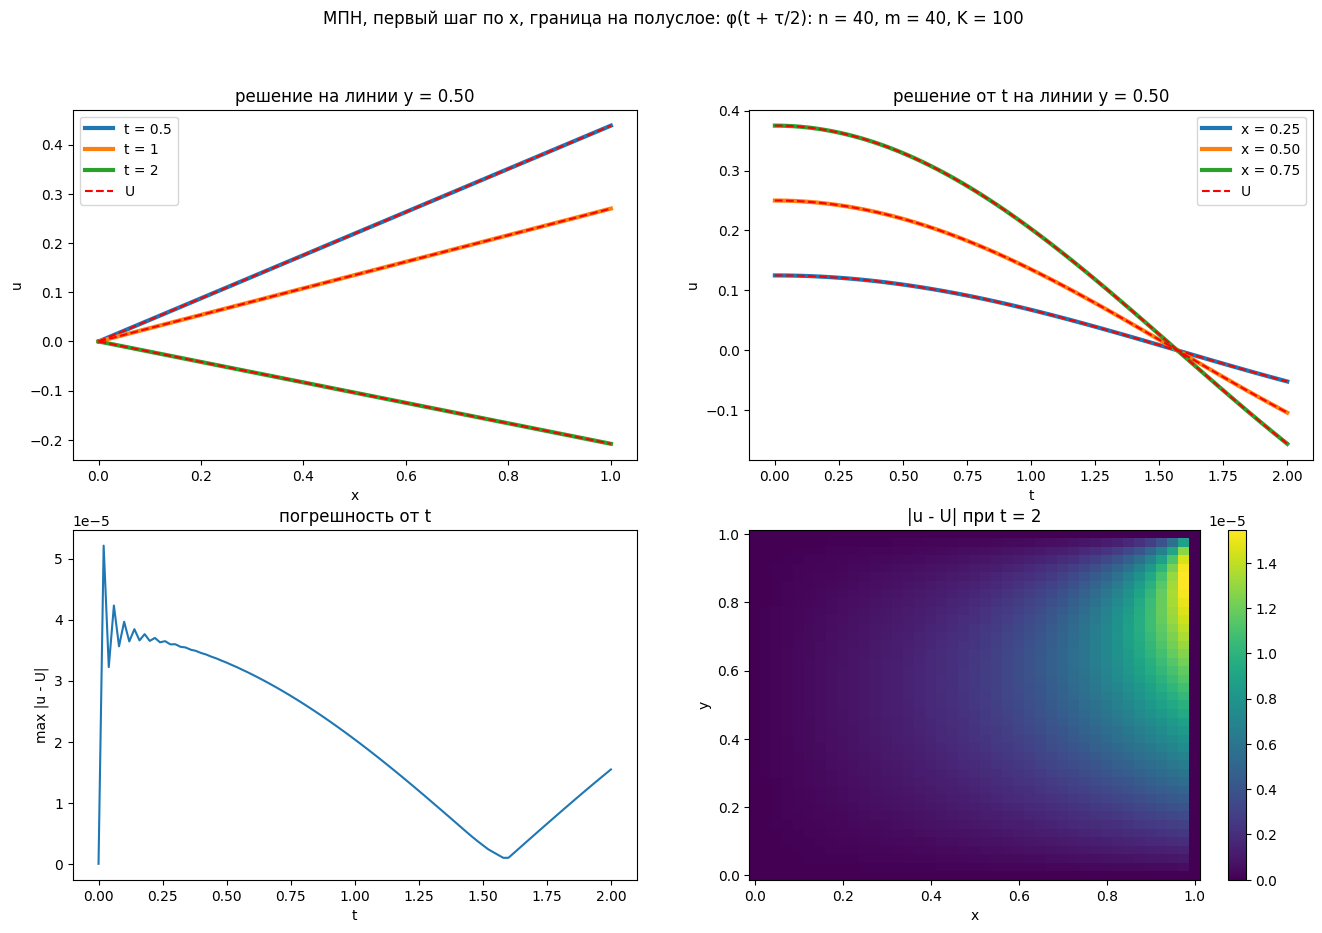

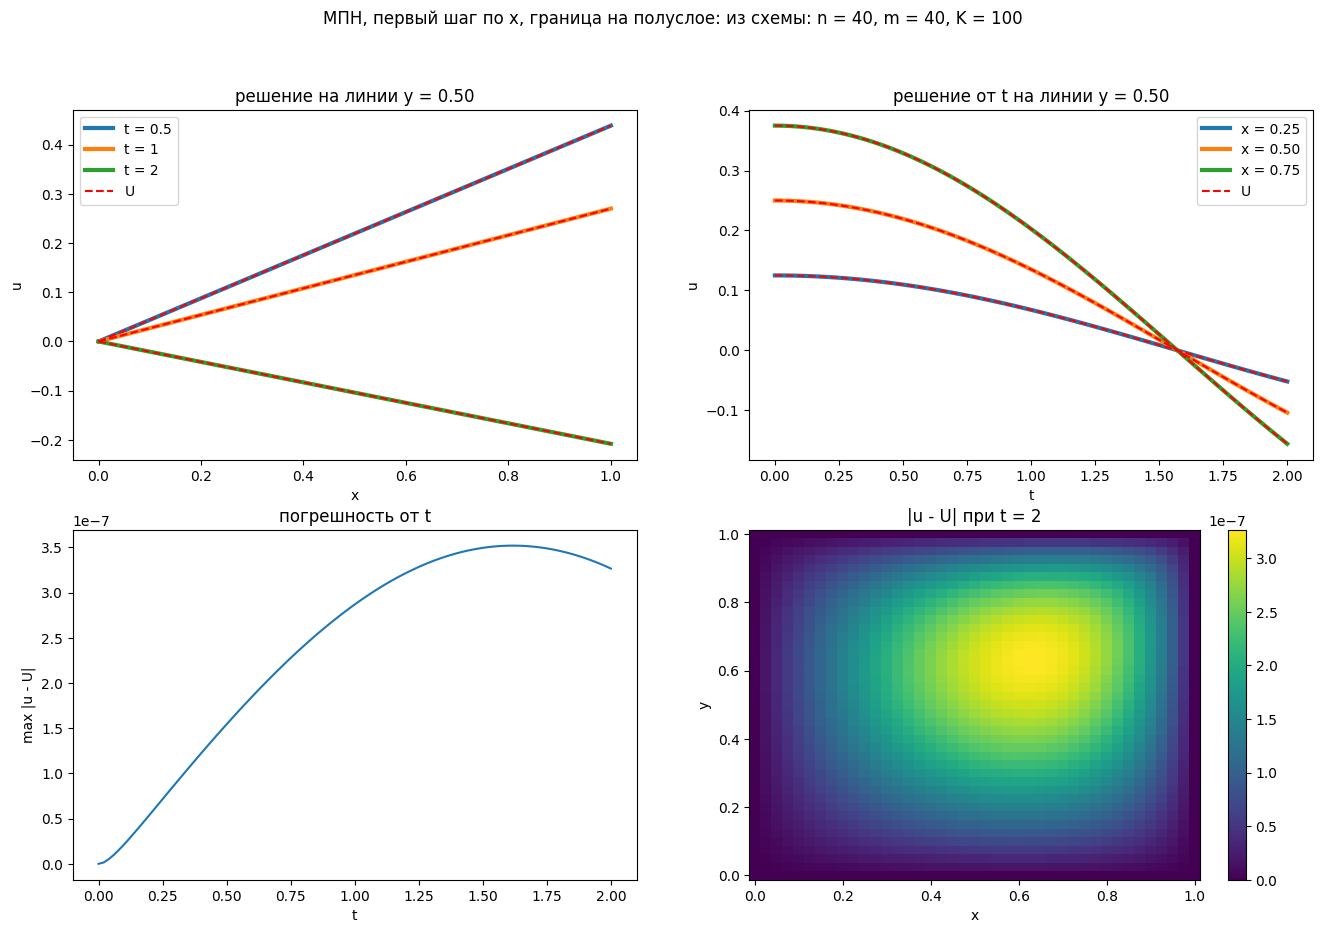

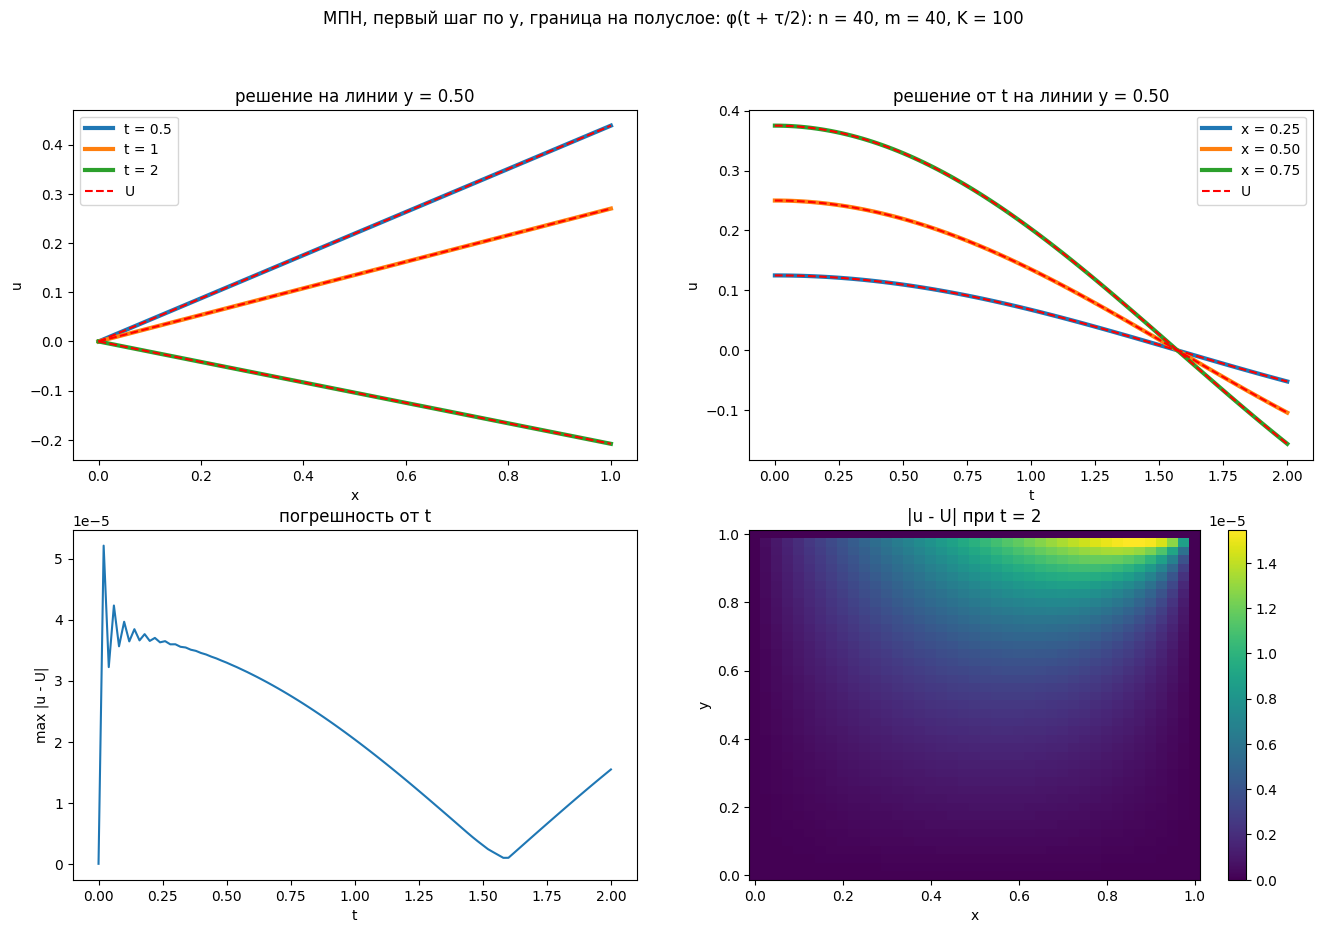

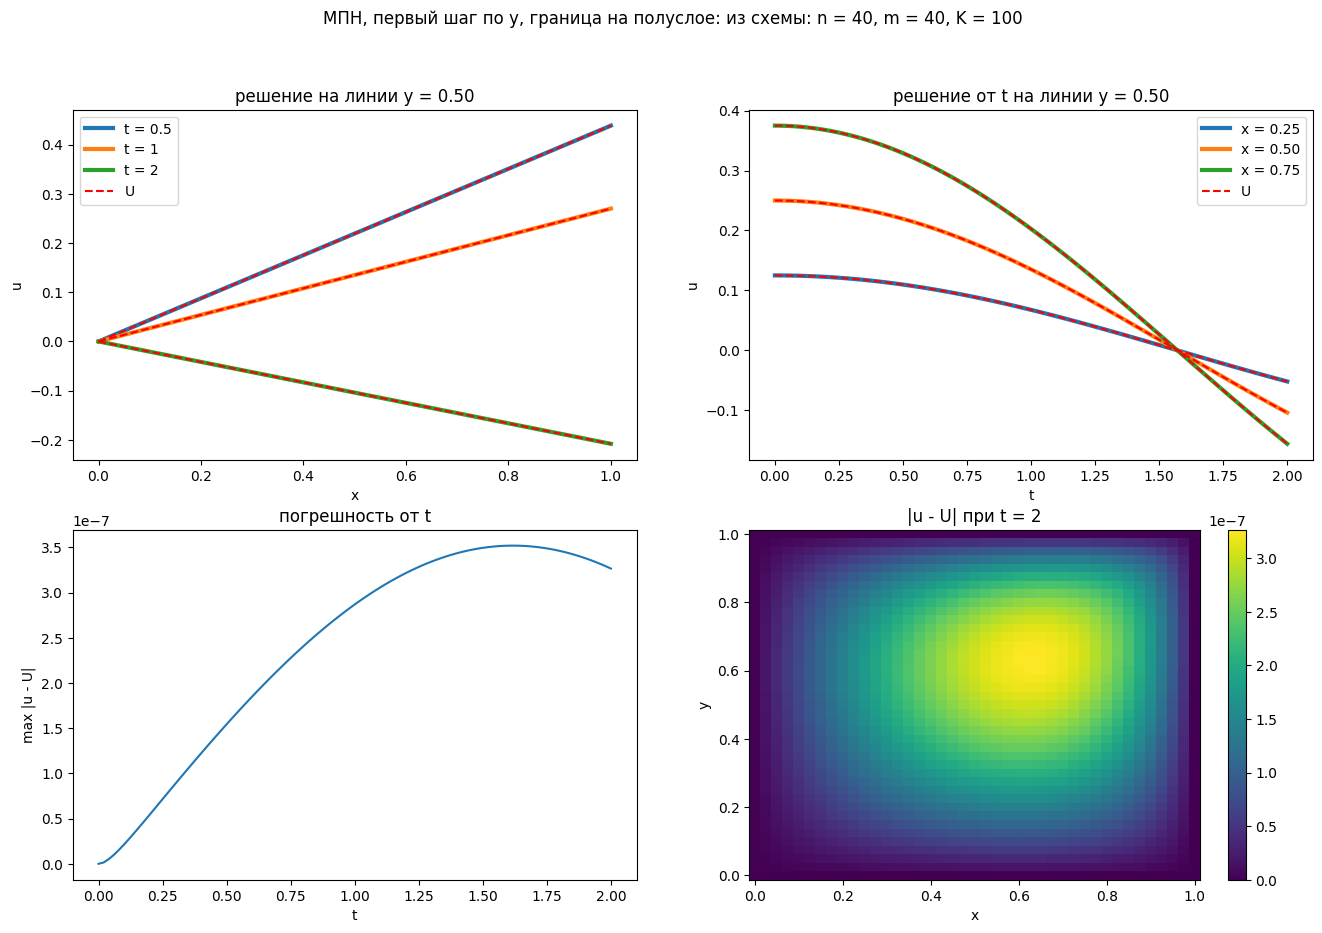

In [10]:
for (scheme_name, first, boundary_name), result in adi_results.items():
    plot_results(result, f'{scheme_name}, первый шаг {first}, граница на полуслое: {boundary_name}')

В обоих вариантах численное решение на графиках совпадает с аналитическим, но погрешности различаются на два порядка.

С $\varphi(t + \tau/2)$ погрешность сосредоточена у границы $x = 1$ (правый нижний график), по времени меняется как $|\cos t|$ и почти обращается в ноль при $t \approx \pi/2$. В первые шаги она ещё и колеблется от шага к шагу.

Объясним это. Во внутренних узлах промежуточный слой связан с целыми слоями соотношением, выведенным выше. На стороне $x = 1$ точное решение $U = y\cos t$ линейно по $y$, поэтому $\Lambda_y U = 0$, и схема «ожидает» на промежуточном слое значение $\frac{1}{2}\left(U^k + U^{k+1}\right)$. Первый вариант ставит вместо него $U(t^{k+1/2})$. По формуле Тейлора

$
U(t^{k+1/2}) - \dfrac{U(t^k) + U(t^{k+1})}{2} = -\dfrac{\tau^2}{8}\dfrac{\partial^2 U}{\partial t^2} + O(\tau^4) = \dfrac{\tau^2}{8}\,xy\cos t^{k+1/2} + O(\tau^4).
$

На стороне $x = 0$ это рассогласование равно нулю, на стороне $x = 1$ - $\frac{\tau^2}{8}y\cos t$: оно наибольшее у $y = 1$ и обращается в ноль при $t = \pi/2$. При $\tau = 0.02$ это $5 \cdot 10^{-5}$ - столько и составляет наибольшая погрешность, $5.2 \cdot 10^{-5}$ на первом шаге.

С граничными значениями «из схемы» рассогласования нет. Погрешность меняется плавно, наибольшая - внутри области, и не превышает $3.5 \cdot 10^{-7}$.

При порядке «сначала по $y$» всё то же самое с заменой $x \leftrightarrow y$. Погрешности во все моменты совпадают, а с $\varphi(t + \tau/2)$ пограничный слой лежит у стороны $y = 1$ - там, где теперь задаются значения на промежуточном слое.

------

# 2. Метод дробных шагов

Метод дробных шагов использует только неявные операторы: на первом дробном шаге - по $x$, на втором - по $y$:

$
\dfrac{u_{ij}^{k+1/2} - u_{ij}^k}{\tau} = a\Lambda_x u_{ij}^{k+1/2} + \dfrac{f_{ij}^k}{2},
$

$
\dfrac{u_{ij}^{k+1} - u_{ij}^{k+1/2}}{\tau} = a\Lambda_y u_{ij}^{k+1} + \dfrac{f_{ij}^{k+1}}{2}.
$

Схема абсолютно устойчива. Каждый дробный шаг аппроксимирует только часть уравнения, полная аппроксимация получается лишь после второго шага (суммарная аппроксимация). Порядок схемы $O(\tau + h_x^2 + h_y^2)$ - первый по времени.

С $r_x = \dfrac{a\tau}{h_x^2}$, $r_y = \dfrac{a\tau}{h_y^2}$ получаем системы вдоль $x$ (при каждом $j$) и вдоль $y$ (при каждом $i$):

$
-r_x u_{i-1,j}^{k+1/2} + (1 + 2r_x)\,u_{ij}^{k+1/2} - r_x u_{i+1,j}^{k+1/2} = u_{ij}^k + \dfrac{\tau}{2}f_{ij}^k,
$

$
-r_y u_{i,j-1}^{k+1} + (1 + 2r_y)\,u_{ij}^{k+1} - r_y u_{i,j+1}^{k+1} = u_{ij}^{k+1/2} + \dfrac{\tau}{2}f_{ij}^{k+1}.
$

Граничные значения на промежуточном слое - те же два варианта. Во втором варианте выразим $u^{k+1/2}$ из второго уравнения схемы и запишем его в граничных узлах $i = 0$, $i = n$:

$
u_{0j}^{k+1/2} = \varphi_3(y_j, t^{k+1}) - a\tau\Lambda_y\varphi_3(y_j, t^{k+1}) - \dfrac{\tau}{2}f_{0j}^{k+1},
$

и так же при $i = n$ с $\varphi_4$.

**Сначала по $y$:**

$
\dfrac{u_{ij}^{k+1/2} - u_{ij}^k}{\tau} = a\Lambda_y u_{ij}^{k+1/2} + \dfrac{f_{ij}^k}{2}, \qquad
\dfrac{u_{ij}^{k+1} - u_{ij}^{k+1/2}}{\tau} = a\Lambda_x u_{ij}^{k+1} + \dfrac{f_{ij}^{k+1}}{2}.
$

Промежуточный слой тогда нужен на сторонах $y = 0$ и $y = l_y$, и во втором варианте

$
u_{i0}^{k+1/2} = \varphi_1(x_i, t^{k+1}) - a\tau\Lambda_x\varphi_1(x_i, t^{k+1}) - \dfrac{\tau}{2}f_{i0}^{k+1},
$

и так же при $j = m$ с $\varphi_2$.

In [11]:
def fractional_steps(grid, half_boundary, first):
    t, tau = grid.t, grid.tau
    flip, h_1, h_2 = orient(grid, first)
    X, Y = np.meshgrid(grid.x, grid.y, indexing='ij')
    r_1, r_2 = a * tau / h_1**2, a * tau / h_2**2

    u = np.zeros((len(t), len(grid.x), len(grid.y)))
    u[0] = psi(X, Y)

    for k in range(len(t) - 1):
        u_k = flip(u[k])
        f_lower, f_upper = flip(f(X, Y, t[k])), flip(f(X, Y, t[k + 1]))

        u_half = flip(boundary_values(grid, t[k] + tau / 2))
        if half_boundary == 'из схемы':
            upper = flip(boundary_values(grid, t[k + 1]))
            for side in (0, -1):
                u_half[side] = upper[side] - a * tau * second_difference(upper[side], h_2) - tau / 2 * f_upper[side]

        rhs = u_k[1:-1, 1:-1] + tau / 2 * f_lower[1:-1, 1:-1]
        u_half[1:-1, 1:-1] = solve_lines(r_1, rhs, u_half[0, 1:-1], u_half[-1, 1:-1])

        u_next = flip(boundary_values(grid, t[k + 1]))
        rhs = u_half[1:-1, 1:-1] + tau / 2 * f_upper[1:-1, 1:-1]
        u_next[1:-1, 1:-1] = solve_lines(r_2, rhs.T, u_next[1:-1, 0], u_next[1:-1, -1]).T

        u[k + 1] = flip(u_next)

    return Result(grid, u)

In [12]:
fs_results = {
    ('МДШ', first, name): fractional_steps(grid, name, first)
    for first in orders
    for name in half_boundaries
}
error_table(fs_results)

t = 0.25       t = 0.5  \
схема первый шаг граница на полуслое                               
МДШ   по x       φ(t + τ/2)           2.595943e-05  2.347922e-05   
                 из схемы             1.192870e-07  2.749503e-07   
      по y       φ(t + τ/2)           2.595943e-05  2.347922e-05   
                 из схемы             1.192870e-07  2.749503e-07   

                                             t = 1       t = 1.5         t = 2  
схема первый шаг граница на полуслое                                            
МДШ   по x       φ(t + τ/2)           1.449435e-05  1.961909e-06  1.105300e-05  
                 из схемы             5.157651e-07  6.303064e-07  5.905266e-07  
      по y       φ(t + τ/2)           1.449435e-05  1.961909e-06  1.105300e-05  
                 из схемы             5.157651e-07  6.303064e-07  5.905266e-07

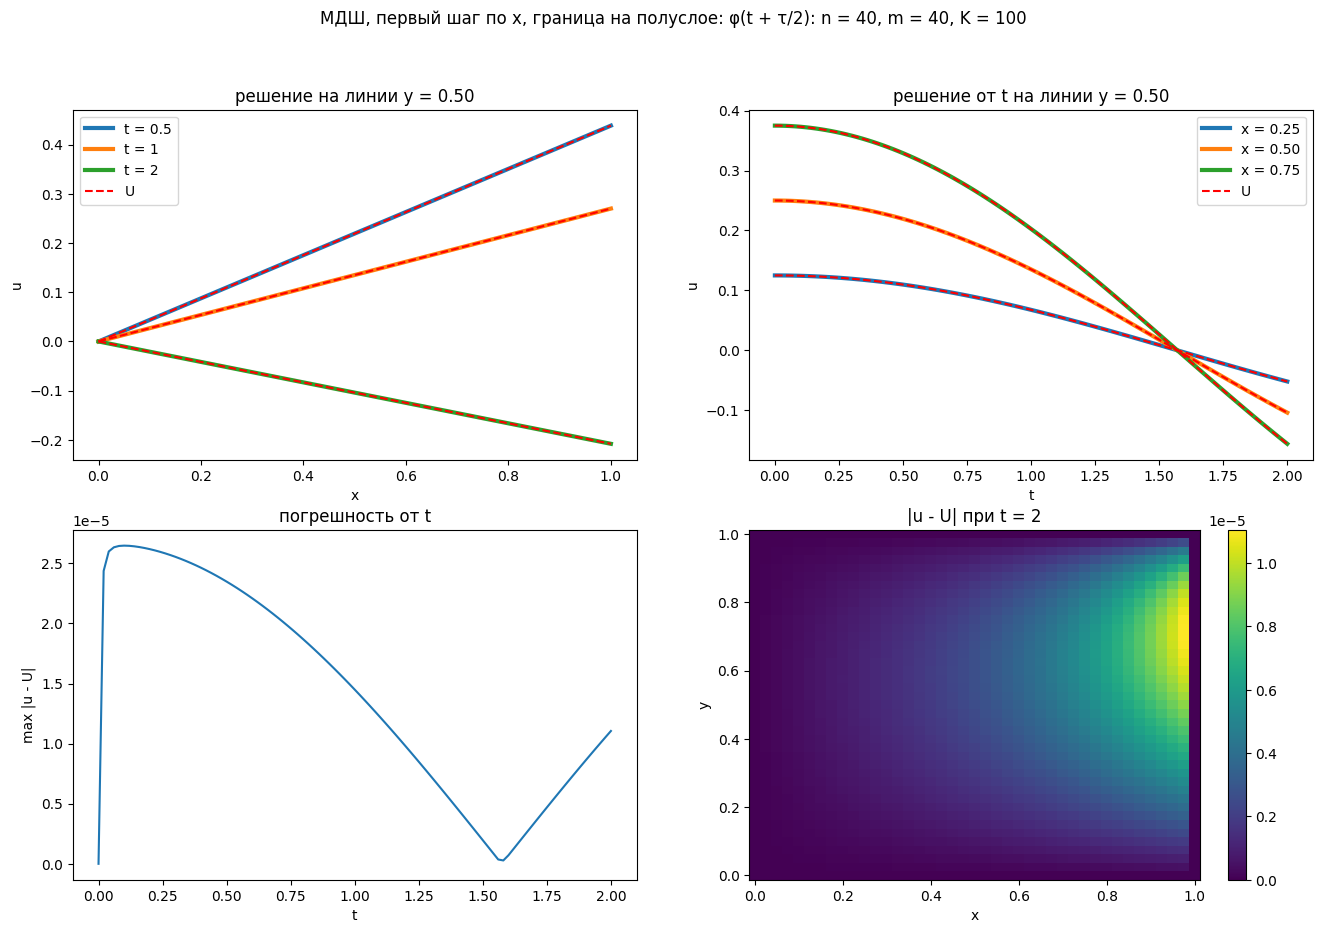

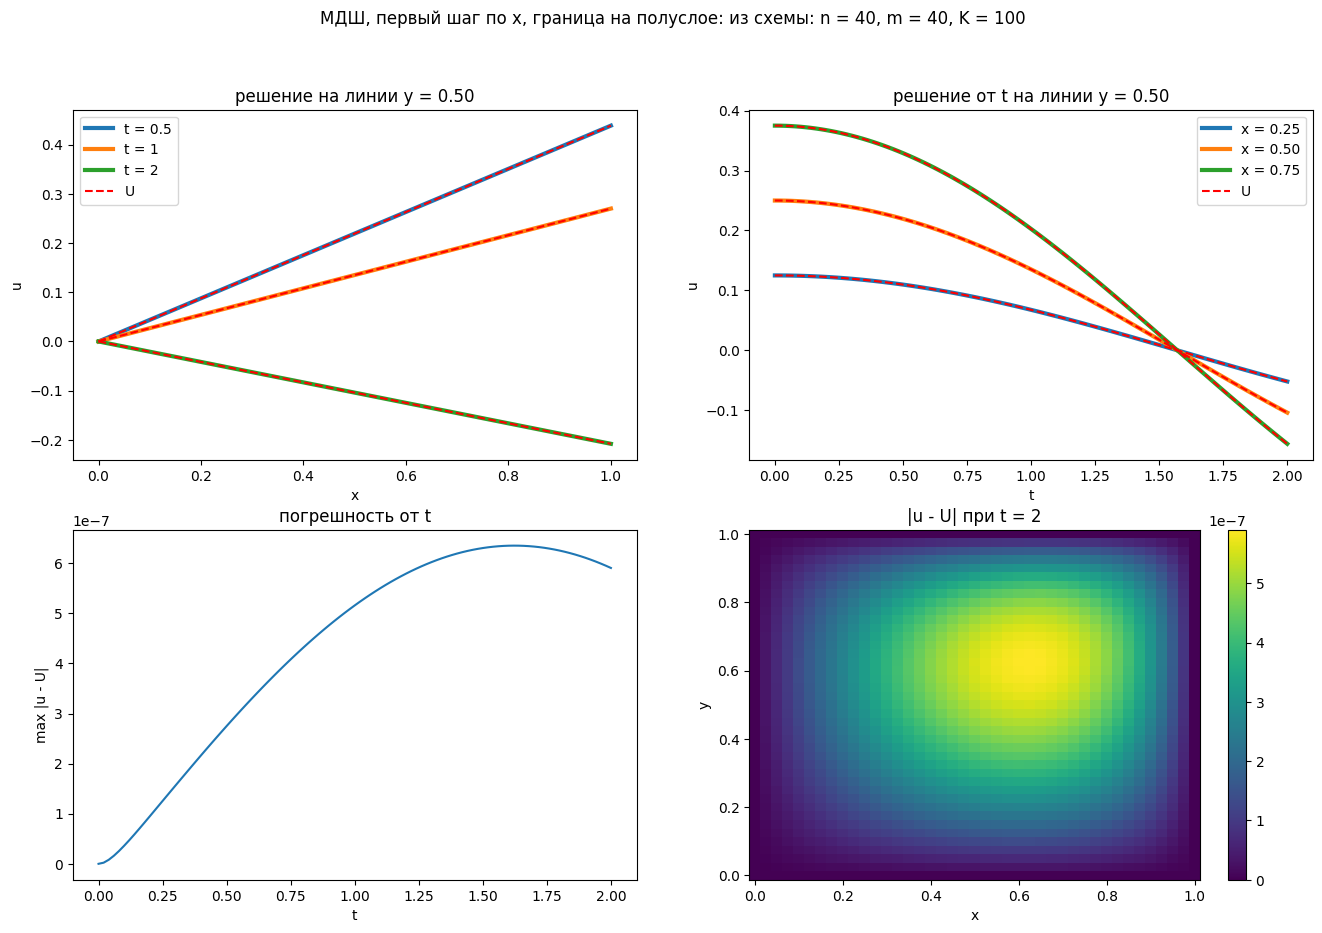

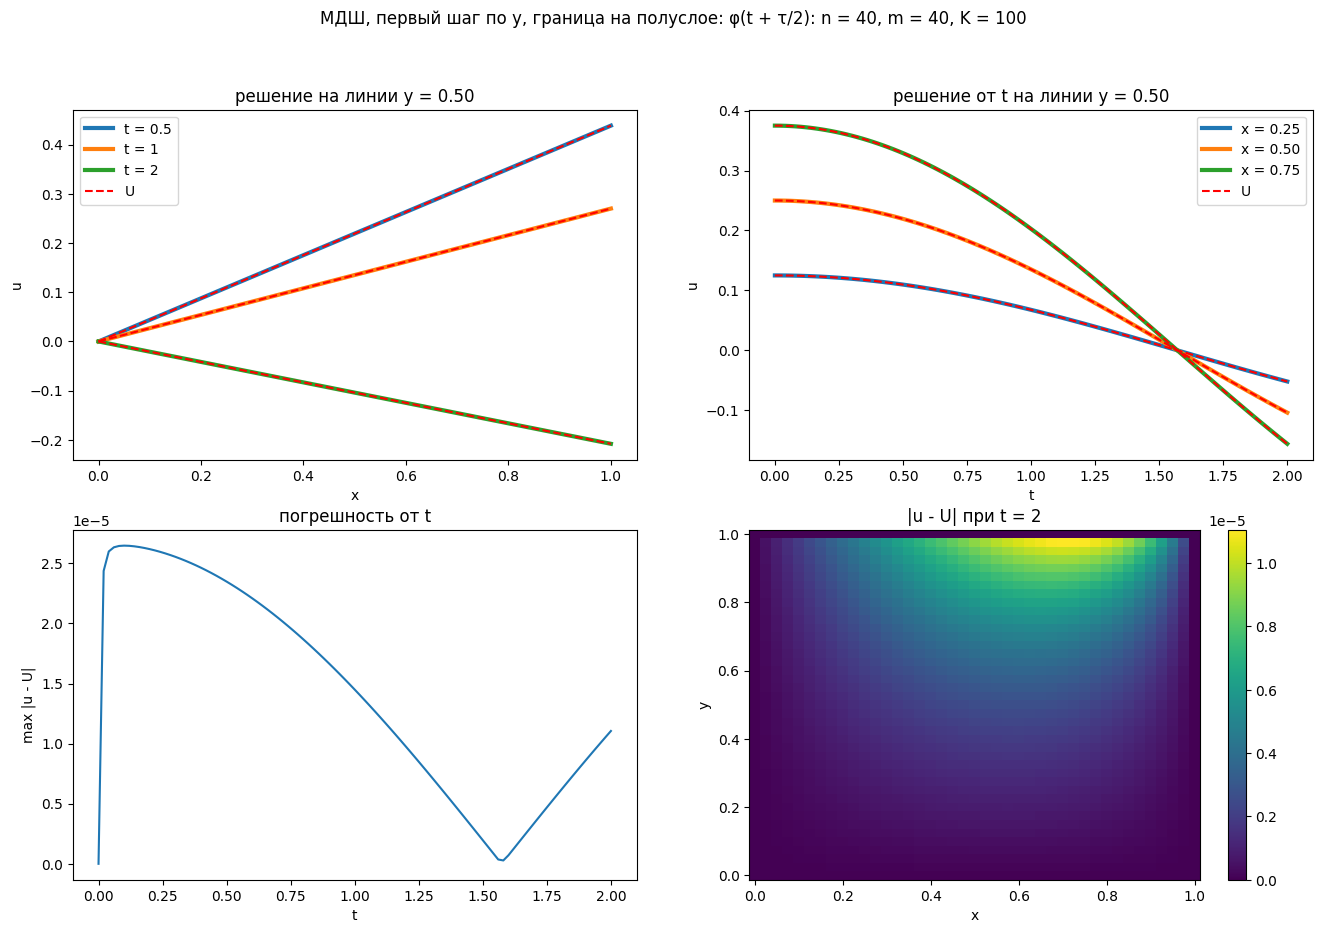

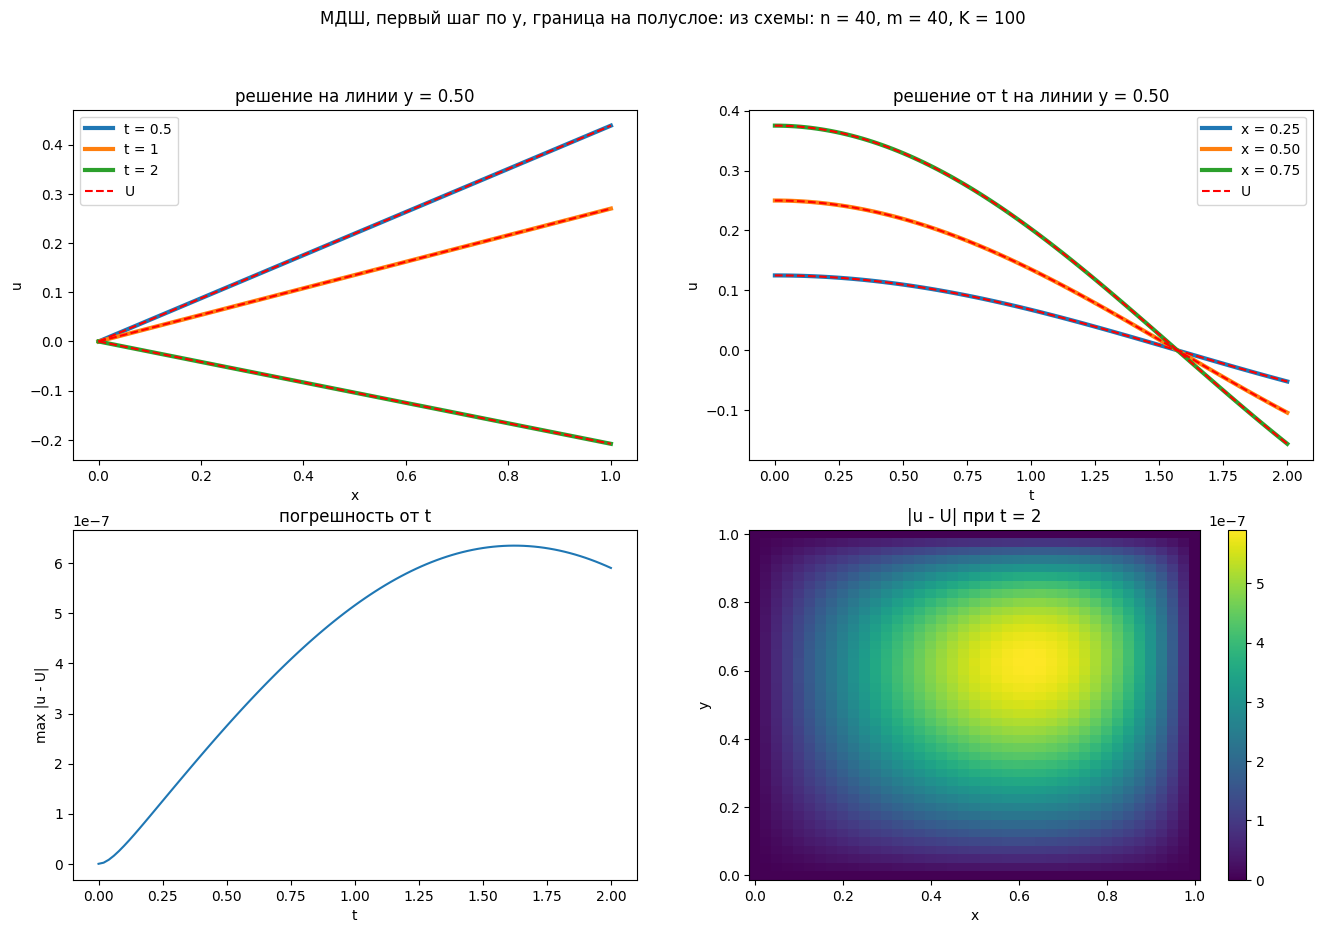

In [13]:
for (scheme_name, first, boundary_name), result in fs_results.items():
    plot_results(result, f'{scheme_name}, первый шаг {first}, граница на полуслое: {boundary_name}')

Картина та же. С $\varphi(t + \tau/2)$ погрешность достигает $2.6 \cdot 10^{-5}$, сосредоточена у границы $x = 1$ и почти обращается в ноль при $t \approx \pi/2$, но без колебаний в начале: в этой схеме оба оператора неявные. С граничными значениями «из схемы» она не больше $6.4 \cdot 10^{-7}$.

Рассогласование здесь того же порядка. На стороне $x = 1$ $\Lambda_y U = 0$, поэтому второе уравнение схемы «ожидает» на промежуточном слое $U^{k+1} - \frac{\tau}{2}f^{k+1}$. Кроме того, $\frac{\partial^2 U}{\partial x^2} + \frac{\partial^2 U}{\partial y^2} = 0$, поэтому из уравнения $\frac{\partial U}{\partial t} = f$, и

$
U(t^{k+1/2}) - \left(U(t^{k+1}) - \dfrac{\tau}{2}\dfrac{\partial U}{\partial t}(t^{k+1})\right) = \dfrac{\tau^2}{8}\dfrac{\partial^2 U}{\partial t^2} + O(\tau^3) = -\dfrac{\tau^2}{8}\,xy\cos t^{k+1/2} + O(\tau^3).
$

При порядке «сначала по $y$» погрешности те же, а пограничный слой с $\varphi(t + \tau/2)$ - у стороны $y = 1$.

------

# 3. Погрешность в различные моменты времени

Сравним обе схемы с обоими вариантами граничных значений на основной сетке:

In [14]:
results = adi_results | fs_results
error_table(results)

t = 0.25       t = 0.5  \
схема первый шаг граница на полуслое                               
МПН   по x       φ(t + τ/2)           3.628763e-05  3.296030e-05   
                 из схемы             6.812902e-08  1.543433e-07   
      по y       φ(t + τ/2)           3.628763e-05  3.296030e-05   
                 из схемы             6.812902e-08  1.543433e-07   
МДШ   по x       φ(t + τ/2)           2.595943e-05  2.347922e-05   
                 из схемы             1.192870e-07  2.749503e-07   
      по y       φ(t + τ/2)           2.595943e-05  2.347922e-05   
                 из схемы             1.192870e-07  2.749503e-07   

                                             t = 1       t = 1.5         t = 2  
схема первый шаг граница на полуслое                                            
МПН   по x       φ(t + τ/2)           2.037693e-05  3.054547e-06  1.545934e-05  
                 из схемы             2.868334e-07  3.494603e-07  3.265272e-07  
      по y       φ(t + τ/2)           2.037693e-05  3.054547e-06  1.545934e-05  
                 из схемы             2.868334e-07  3.494603e-07  3.265272e-07  
МДШ   по x       φ(t + τ/2)           1.449435e-05  1.961909e-06  1.105300e-05  
                 из схемы             5.157651e-07  6.303064e-07  5.905266e-07  
      по y       φ(t + τ/2)           1.449435e-05  1.961909e-06  1.105300e-05  
                 из схемы             5.157651e-07  6.303064e-07  5.905266e-07

Задача симметрична относительно замены $x \leftrightarrow y$: функции $U = xy\cos t$ и $f = -xy\sin t$ не меняются, $\varphi_1 = \varphi_3 = 0$, а $\varphi_2(x, t) = x\cos t$ переходит в $\varphi_4(y, t) = y\cos t$. Поэтому при $n = m$ решение «сначала по $y$» должно совпасть с транспонированным решением «сначала по $x$». Проверим:

In [15]:
for scheme_name in ['МПН', 'МДШ']:
    for name in half_boundaries:
        u_by_x = results[(scheme_name, 'по x', name)].u
        u_by_y = results[(scheme_name, 'по y', name)].u
        print(f'{scheme_name}, {name}: max |u(по y) - u(по x)^T| = {np.abs(u_by_y - u_by_x.transpose(0, 2, 1)).max():.1e}')

МПН, φ(t + τ/2): max |u(по y) - u(по x)^T| = 0.0e+00
МПН, из схемы: max |u(по y) - u(по x)^T| = 0.0e+00
МДШ, φ(t + τ/2): max |u(по y) - u(по x)^T| = 0.0e+00
МДШ, из схемы: max |u(по y) - u(по x)^T| = 0.0e+00


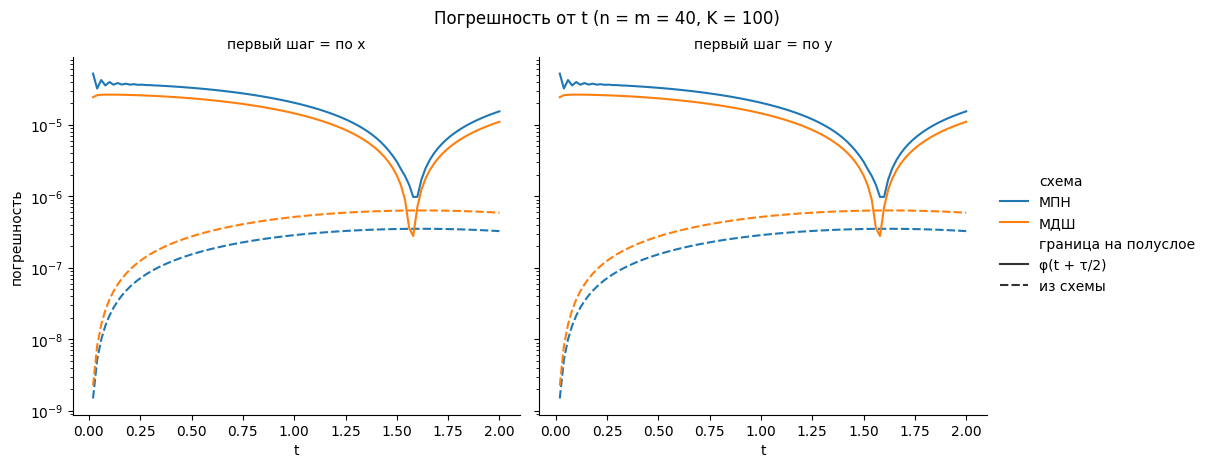

In [16]:
history = pd.concat([
    pd.DataFrame({
        't': result.grid.t[1:],
        'погрешность': error(result)[1:],
        'схема': scheme_name,
        'первый шаг': first,
        'граница на полуслое': boundary_name,
    })
    for (scheme_name, first, boundary_name), result in results.items()
])

g = sns.relplot(data=history, x='t', y='погрешность', hue='схема', style='граница на полуслое', col='первый шаг',
                kind='line', height=4.5, aspect=1.1)
g.set(yscale='log')
g.figure.suptitle(f'Погрешность от t (n = m = {n}, K = {K})', y=1.03);

- С $\varphi(t + \tau/2)$ погрешность обеих схем определяется рассогласованием на границе. Она пропорциональна $|\cos t|$ и проваливается почти до нуля при $t \approx \pi/2 \approx 1.57$: минимум $9.8 \cdot 10^{-7}$ у МПН и $2.8 \cdot 10^{-7}$ у МДШ. Поэтому при $t = 1.5$ варианты различаются всего в 9 раз (МПН) и в 3 раза (МДШ). У МПН в первые шаги погрешность колеблется.
- С граничными значениями «из схемы» погрешность растёт с нуля, к $t \approx 1.5$ выходит на уровень $3.5 \cdot 10^{-7}$ (МПН) и $6.3 \cdot 10^{-7}$ (МДШ) и дальше почти не меняется.
- С граничными значениями «из схемы» МПН примерно вдвое точнее МДШ, а с $\varphi(t + \tau/2)$ - наоборот, МДШ точнее.
- Порядок направлений на погрешность не влияет: решение «сначала по $y$» совпадает с транспонированным решением «сначала по $x$» точно, расхождение $0$. Поэтому графики для двух порядков одинаковы.

------

# 4. Зависимость погрешности от $\tau$

Фиксируем пространственную сетку $n = m = 40$ и уменьшаем $\tau$ вдвое. Порядок по $\tau$ считаем как $p = \log_2(\varepsilon_\tau / \varepsilon_{\tau/2})$: если $\varepsilon \approx C\tau^p$, то $\varepsilon_\tau / \varepsilon_{\tau/2} = 2^p$.

In [17]:
schemes = {'МПН': alternating_directions, 'МДШ': fractional_steps}


def convergence_study(grids):
    rows = []

    for scheme_name, scheme in schemes.items():
        for first in orders:
            for boundary_name in half_boundaries:
                previous = None

                for n_, m_, K_ in grids:
                    grid_ = make_grid(n_, m_, K_)
                    eps_ = error(scheme(grid_, boundary_name, first)).max()
                    rows.append({
                        'схема': scheme_name,
                        'первый шаг': first,
                        'граница на полуслое': boundary_name,
                        'h_x': grid_.h_x,
                        'h_y': grid_.h_y,
                        'tau': grid_.tau,
                        'погрешность': eps_,
                        'порядок': np.log2(previous / eps_) if previous is not None else np.nan,
                    })
                    previous = eps_

    return pd.DataFrame(rows)


def study_table(study, step):
    return study.pivot_table(index=['схема', 'первый шаг', 'граница на полуслое'], columns=step, values=['погрешность', 'порядок'], sort=False)


def plot_study(study, step, title, slopes=()):
    g = sns.relplot(data=study, x=step, y='погрешность', hue='схема', style='граница на полуслое', col='первый шаг',
                    kind='line', markers=True, height=4.5, aspect=1.1)

    steps = np.sort(study[step].unique())
    anchor = study.loc[study[step] == steps[-1], 'погрешность'].median()
    for ax in g.axes.flat:
        references = [
            ax.plot(steps, anchor * (steps / steps[-1]) ** slope, color='gray', linestyle=linestyle, label=f'~ {step}^{slope}')[0]
            for slope, linestyle in zip(slopes, [':', '-.'])
        ]
        if references:
            ax.legend(handles=references, loc='lower right')

    g.set(xscale='log', yscale='log')
    g.figure.suptitle(title, y=1.03)


K_list = [10, 20, 40, 80, 160, 320]

tau_study = convergence_study([(n, m, k) for k in K_list])
study_table(tau_study, 'tau')

погрешность                      \
tau                                      0.20000   0.10000   0.05000   
схема первый шаг граница на полуслое                                   
МПН   по x       φ(t + τ/2)             0.003050  0.000986  0.000293   
                 из схемы               0.000035  0.000009  0.000002   
      по y       φ(t + τ/2)             0.003050  0.000986  0.000293   
                 из схемы               0.000035  0.000009  0.000002   
МДШ   по x       φ(t + τ/2)             0.000999  0.000375  0.000127   
                 из схемы               0.000034  0.000011  0.000003   
      по y       φ(t + τ/2)             0.000999  0.000375  0.000127   
                 из схемы               0.000034  0.000011  0.000003   

                                                                  \
tau                                        0.02500       0.01250   
схема первый шаг граница на полуслое                               
МПН   по x       φ(t + τ/2)           8.032001e-05  2.051182e-05   
                 из схемы             5.498434e-07  1.374588e-07   
      по y       φ(t + τ/2)           8.032001e-05  2.051182e-05   
                 из схемы             5.498434e-07  1.374588e-07   
МДШ   по x       φ(t + τ/2)           3.927906e-05  1.133290e-05   
                 из схемы             9.689120e-07  2.574551e-07   
      по y       φ(t + τ/2)           3.927906e-05  1.133290e-05   
                 из схемы             9.689120e-07  2.574551e-07   

                                                     порядок            \
tau                                        0.00625   0.10000   0.05000   
схема первый шаг граница на полуслое                                     
МПН   по x       φ(t + τ/2)           4.889330e-06  1.629464  1.748865   
                 из схемы             3.436491e-08  1.996501  1.999976   
      по y       φ(t + τ/2)           4.889330e-06  1.629464  1.748865   
                 из схемы             3.436491e-08  1.996501  1.999976   
МДШ   по x       φ(t + τ/2)           3.124234e-06  1.411651  1.561881   
                 из схемы             6.646494e-08  1.572507  1.727492   
      по y       φ(t + τ/2)           3.124234e-06  1.411651  1.561881   
                 из схемы             6.646494e-08  1.572507  1.727492   

                                                                    
tau                                    0.02500   0.01250   0.00625  
схема первый шаг граница на полуслое                                
МПН   по x       φ(t + τ/2)           1.868461  1.969304  2.068747  
                 из схемы             1.999853  2.000021  1.999992  
      по y       φ(t + τ/2)           1.868461  1.969304  2.068747  
                 из схемы             1.999853  2.000021  1.999992  
МДШ   по x       φ(t + τ/2)           1.694834  1.793244  1.858943  
                 из схемы             1.839148  1.912045  1.953655  
      по y       φ(t + τ/2)           1.694834  1.793244  1.858943  
                 из схемы             1.839148  1.912045  1.953655

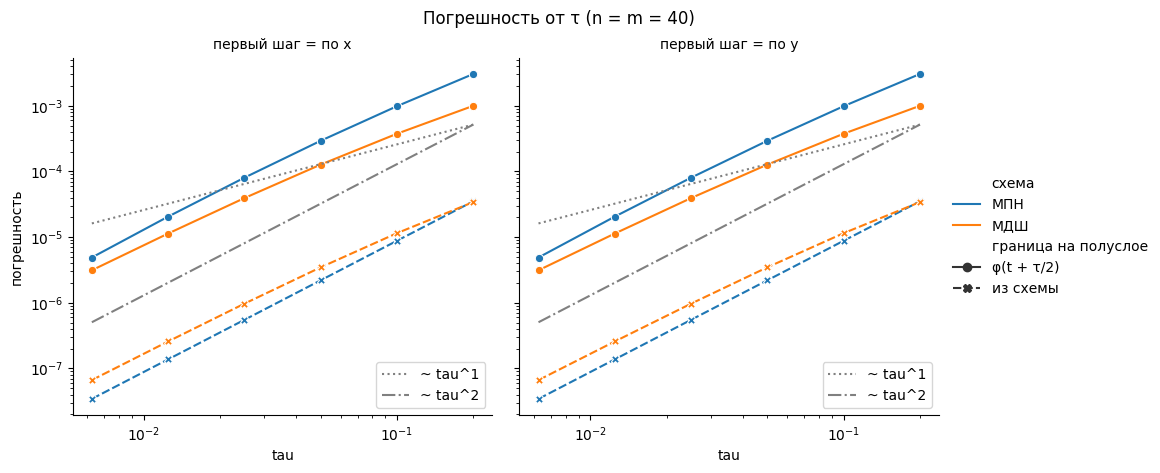

In [18]:
plot_study(tau_study, 'tau', f'Погрешность от τ (n = m = {n})', slopes=(1, 2))

- **МПН, «из схемы»:** порядок 2.00 во всём диапазоне - второй порядок по времени, как и должно быть у этой схемы.
- **МПН, $\varphi(t + \tau/2)$:** порядок растёт от 1.63 до 2.07 и приближается к 2. Рассогласование на границе тоже $O(\tau^2)$, поэтому порядок в пределе второй, но погрешность в 90–140 раз больше.
- **МДШ:** у схемы первый порядок по времени, но здесь порядок в обоих вариантах растёт к 2: от 1.41 до 1.86 с $\varphi(t + \tau/2)$ и от 1.57 до 1.95 «из схемы».

Почему МДШ ведёт себя как схема второго порядка. Пусть на слое $t^k$ численное решение совпадает с точным: $u^k = U^k$. Функции $U$ и $f = -xy\sin t$ линейны по $x$ и по $y$, поэтому $\Lambda_x$ и $\Lambda_y$ от них равны нулю. Тогда первому уравнению схемы удовлетворяет $u^{k+1/2} = U^k + \frac{\tau}{2}f^k$, а второму - $u^{k+1} = U^k + \frac{\tau}{2}\left(f^k + f^{k+1}\right)$. Для нашего решения $\frac{\partial U}{\partial t} = f$, и это формула трапеций для $U^{k+1} = U^k + \int_{t^k}^{t^{k+1}} f\,dt$. Её ошибка на шаге $O(\tau^3)$, а на всём отрезке $O(\tau^2)$. Значит, на этом решении первый порядок МДШ проявиться не может.

МПН таким же рассуждением сводится к формуле средних прямоугольников: $u^{k+1} = U^k + \tau f^{k+1/2}$.

Для обоих порядков направлений результаты совпадают до последнего знака - по той же причине, что и на основной сетке.

------

# 5. Зависимость погрешности от $h_x$ и $h_y$

Фиксируем $K = 100$ ($\tau = 0.02$) и измельчаем пространственную сетку.

## Одинаковые шаги $h_x = h_y$

In [19]:
N_list = [5, 10, 20, 40, 80]

h_study = convergence_study([(k, k, K) for k in N_list])
study_table(h_study, 'h_x')

погрешность                \
h_x                                         0.2000        0.1000   
схема первый шаг граница на полуслое                               
МПН   по x       φ(t + τ/2)           1.653667e-05  2.504612e-05   
                 из схемы             3.374164e-07  3.459909e-07   
      по y       φ(t + τ/2)           1.653667e-05  2.504612e-05   
                 из схемы             3.374164e-07  3.459909e-07   
МДШ   по x       φ(t + τ/2)           1.443896e-05  2.038753e-05   
                 из схемы             6.132150e-07  6.272122e-07   
      по y       φ(t + τ/2)           1.443896e-05  2.038753e-05   
                 из схемы             6.132150e-07  6.272122e-07   

                                                                  \
h_x                                         0.0500        0.0250   
схема первый шаг граница на полуслое                               
МПН   по x       φ(t + τ/2)           4.058537e-05  5.213088e-05   
                 из схемы             3.507267e-07  3.519030e-07   
      по y       φ(t + τ/2)           4.058537e-05  5.213088e-05   
                 из схемы             3.507267e-07  3.519030e-07   
МДШ   по x       φ(t + τ/2)           2.425025e-05  2.647320e-05   
                 из схемы             6.308672e-07  6.351076e-07   
      по y       φ(t + τ/2)           2.425025e-05  2.647320e-05   
                 из схемы             6.308672e-07  6.351076e-07   

                                                     порядок            \
h_x                                         0.0125    0.1000    0.0500   
схема первый шаг граница на полуслое                                     
МПН   по x       φ(t + τ/2)           5.907957e-05 -0.598919 -0.696373   
                 из схемы             3.522534e-07 -0.036204 -0.019613   
      по y       φ(t + τ/2)           5.907957e-05 -0.598919 -0.696373   
                 из схемы             3.522534e-07 -0.036204 -0.019613   
МДШ   по x       φ(t + τ/2)           2.770653e-05 -0.497720 -0.250313   
                 из схемы             6.353480e-07 -0.032561 -0.008383   
      по y       φ(t + τ/2)           2.770653e-05 -0.497720 -0.250313   
                 из схемы             6.353480e-07 -0.032561 -0.008383   

                                                          
h_x                                     0.0250    0.0125  
схема первый шаг граница на полуслое                      
МПН   по x       φ(t + τ/2)          -0.361179 -0.180521  
                 из схемы            -0.004831 -0.001436  
      по y       φ(t + τ/2)          -0.361179 -0.180521  
                 из схемы            -0.004831 -0.001436  
МДШ   по x       φ(t + τ/2)          -0.126533 -0.065694  
                 из схемы            -0.009665 -0.000546  
      по y       φ(t + τ/2)          -0.126533 -0.065694  
                 из схемы            -0.009665 -0.000546

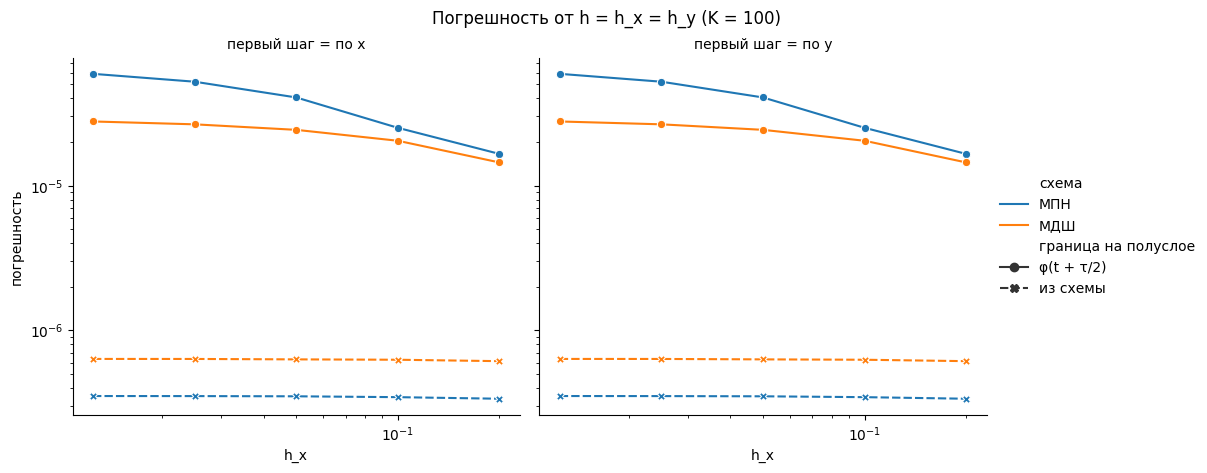

In [20]:
plot_study(h_study, 'h_x', f'Погрешность от h = h_x = h_y (K = {K})')

- **«Из схемы»:** погрешность от $h$ не зависит. При уменьшении $h$ в 16 раз она меняется у МПН от $3.37 \cdot 10^{-7}$ до $3.52 \cdot 10^{-7}$, у МДШ - от $6.13 \cdot 10^{-7}$ до $6.35 \cdot 10^{-7}$, порядок близок к нулю. Так и должно быть: разностные производные на нашем решении точны, и вся погрешность - от шага по времени.
- **$\varphi(t + \tau/2)$:** при измельчении сетки погрешность не убывает, а растёт - у МПН с $1.7 \cdot 10^{-5}$ до $5.9 \cdot 10^{-5}$, у МДШ с $1.4 \cdot 10^{-5}$ до $2.8 \cdot 10^{-5}$ - и выходит на постоянный уровень.

Причина - в том, как рассогласование на границе $x = 1$ проникает внутрь области. Прогонка по $x$ решает систему $-r w_{s-1} + (1 + 2r) w_s - r w_{s+1} = d_s$. Возмущение граничного значения удовлетворяет однородному уравнению, его решения $w_s = q^s$, где $rq^2 - (1 + 2r)q + r = 0$. Убывающий корень

$
q = \dfrac{1 + 2r - \sqrt{1 + 4r}}{2r},
$

то есть в каждом следующем узле от границы возмущение умножается на $q$. Пересчитанное на расстояние, оно убывает в $e$ раз на длине $L = -h/\ln q$. При $\tau = 0.02$ это $L \approx 0.10$ у МПН ($r = a\tau/(2h^2)$) и $L \approx 0.14$ у МДШ ($r = a\tau/h^2$) практически при любом $h$, примерно $\sqrt{a\tau/2}$ и $\sqrt{a\tau}$. Ближайший к границе внутренний узел находится на расстоянии $h_x$ от неё и получает долю $q$ рассогласования: у МПН при $h_x = 0.2$ это $q = 0.17$, а при $h_x = 0.0125$ - уже $q = 0.88$. Чем мельче сетка по $x$, тем больше узлов попадает в пограничный слой шириной $L$ и тем ближе погрешность к самому рассогласованию.

При $h_x = h_y$ оба порядка направлений дают одинаковые результаты: решения совпадают с точностью до транспонирования.

## Только $h_x$ ($m = 40$)

In [21]:
h_x_study = convergence_study([(k, m, K) for k in N_list])
study_table(h_x_study, 'h_x')

погрешность                \
h_x                                         0.2000        0.1000   
схема первый шаг граница на полуслое                               
МПН   по x       φ(t + τ/2)           1.754942e-05  2.560462e-05   
                 из схемы             3.443285e-07  3.488040e-07   
      по y       φ(t + τ/2)           4.897035e-05  5.097106e-05   
                 из схемы             3.443285e-07  3.488040e-07   
МДШ   по x       φ(t + τ/2)           1.495413e-05  2.053338e-05   
                 из схемы             6.237598e-07  6.310025e-07   
      по y       φ(t + τ/2)           2.432523e-05  2.625026e-05   
                 из схемы             6.237598e-07  6.310025e-07   

                                                                  \
h_x                                         0.0500        0.0250   
схема первый шаг граница на полуслое                               
МПН   по x       φ(t + τ/2)           4.077902e-05  5.213088e-05   
                 из схемы             3.512039e-07  3.519030e-07   
      по y       φ(t + τ/2)           5.188332e-05  5.213088e-05   
                 из схемы             3.512039e-07  3.519030e-07   
МДШ   по x       φ(t + τ/2)           2.428821e-05  2.647320e-05   
                 из схемы             6.328701e-07  6.351076e-07   
      по y       φ(t + τ/2)           2.641818e-05  2.647320e-05   
                 из схемы             6.328701e-07  6.351076e-07   

                                                     порядок            \
h_x                                         0.0125    0.1000    0.0500   
схема первый шаг граница на полуслое                                     
МПН   по x       φ(t + τ/2)           5.903890e-05 -0.544980 -0.671423   
                 из схемы             3.520488e-07 -0.018631 -0.009892   
      по y       φ(t + τ/2)           5.216679e-05 -0.057770 -0.025592   
                 из схемы             3.520488e-07 -0.018631 -0.009892   
МДШ   по x       φ(t + τ/2)           2.769390e-05 -0.457428 -0.242285   
                 из схемы             6.352278e-07 -0.016655 -0.004264   
      по y       φ(t + τ/2)           2.650252e-05 -0.109878 -0.009199   
                 из схемы             6.352278e-07 -0.016655 -0.004264   

                                                          
h_x                                     0.0250    0.0125  
схема первый шаг граница на полуслое                      
МПН   по x       φ(t + τ/2)          -0.354311 -0.179528  
                 из схемы            -0.002869 -0.000598  
      по y       φ(t + τ/2)          -0.006867 -0.000993  
                 из схемы            -0.002869 -0.000598  
МДШ   по x       φ(t + τ/2)          -0.124277 -0.065036  
                 из схемы            -0.005092 -0.000273  
      по y       φ(t + τ/2)          -0.003002 -0.001597  
                 из схемы            -0.005092 -0.000273

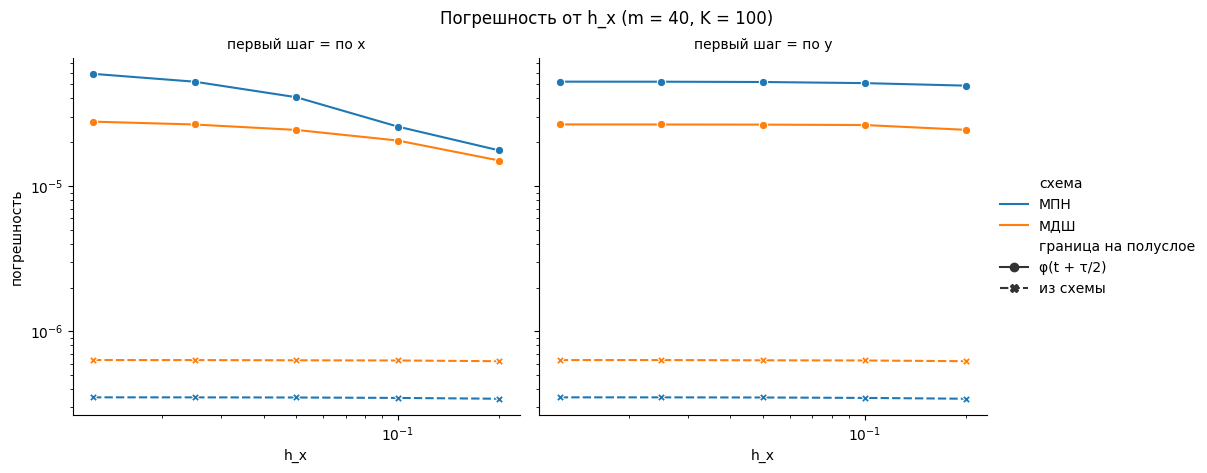

In [22]:
plot_study(h_x_study, 'h_x', f'Погрешность от h_x (m = {m}, K = {K})')

## Только $h_y$ ($n = 40$)

In [23]:
h_y_study = convergence_study([(n, k, K) for k in N_list])
study_table(h_y_study, 'h_y')

погрешность                \
h_y                                         0.2000        0.1000   
схема первый шаг граница на полуслое                               
МПН   по x       φ(t + τ/2)           4.897035e-05  5.097106e-05   
                 из схемы             3.443285e-07  3.488040e-07   
      по y       φ(t + τ/2)           1.754942e-05  2.560462e-05   
                 из схемы             3.443285e-07  3.488040e-07   
МДШ   по x       φ(t + τ/2)           2.432523e-05  2.625026e-05   
                 из схемы             6.237598e-07  6.310025e-07   
      по y       φ(t + τ/2)           1.495413e-05  2.053338e-05   
                 из схемы             6.237598e-07  6.310025e-07   

                                                                  \
h_y                                         0.0500        0.0250   
схема первый шаг граница на полуслое                               
МПН   по x       φ(t + τ/2)           5.188332e-05  5.213088e-05   
                 из схемы             3.512039e-07  3.519030e-07   
      по y       φ(t + τ/2)           4.077902e-05  5.213088e-05   
                 из схемы             3.512039e-07  3.519030e-07   
МДШ   по x       φ(t + τ/2)           2.641818e-05  2.647320e-05   
                 из схемы             6.328701e-07  6.351076e-07   
      по y       φ(t + τ/2)           2.428821e-05  2.647320e-05   
                 из схемы             6.328701e-07  6.351076e-07   

                                                     порядок            \
h_y                                         0.0125    0.1000    0.0500   
схема первый шаг граница на полуслое                                     
МПН   по x       φ(t + τ/2)           5.216679e-05 -0.057770 -0.025592   
                 из схемы             3.520488e-07 -0.018631 -0.009892   
      по y       φ(t + τ/2)           5.903890e-05 -0.544980 -0.671423   
                 из схемы             3.520488e-07 -0.018631 -0.009892   
МДШ   по x       φ(t + τ/2)           2.650252e-05 -0.109878 -0.009199   
                 из схемы             6.352278e-07 -0.016655 -0.004264   
      по y       φ(t + τ/2)           2.769390e-05 -0.457428 -0.242285   
                 из схемы             6.352278e-07 -0.016655 -0.004264   

                                                          
h_y                                     0.0250    0.0125  
схема первый шаг граница на полуслое                      
МПН   по x       φ(t + τ/2)          -0.006867 -0.000993  
                 из схемы            -0.002869 -0.000598  
      по y       φ(t + τ/2)          -0.354311 -0.179528  
                 из схемы            -0.002869 -0.000598  
МДШ   по x       φ(t + τ/2)          -0.003002 -0.001597  
                 из схемы            -0.005092 -0.000273  
      по y       φ(t + τ/2)          -0.124277 -0.065036  
                 из схемы            -0.005092 -0.000273

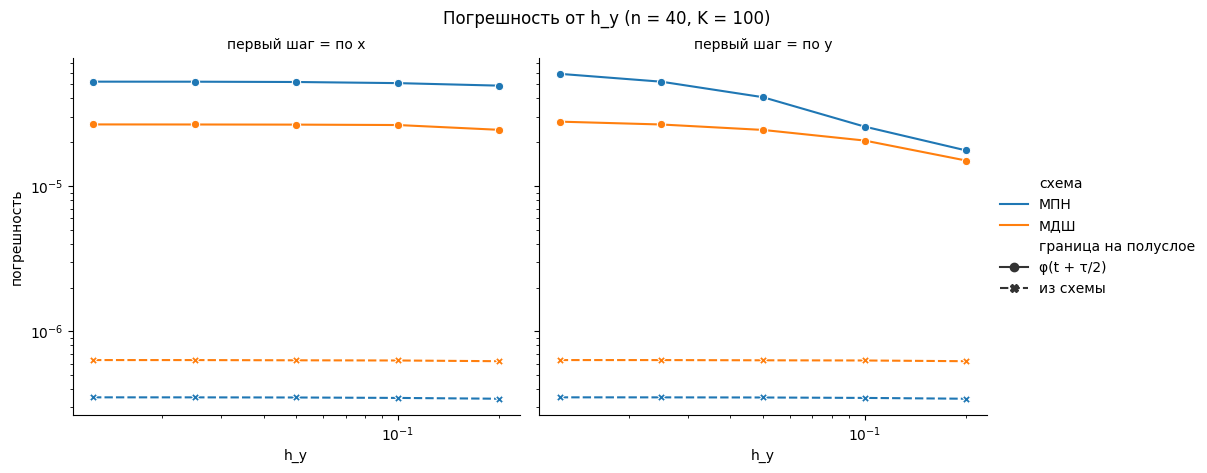

In [24]:
plot_study(h_y_study, 'h_y', f'Погрешность от h_y (n = {n}, K = {K})')

С граничными значениями «из схемы» погрешность не зависит ни от $h_x$, ни от $h_y$ - при обоих порядках направлений.

С $\varphi(t + \tau/2)$ погрешность зависит только от шага в том направлении, с которого начинается шаг по времени:

- **сначала по $x$:** при измельчении по $x$ погрешность растёт у МПН с $1.8 \cdot 10^{-5}$ до $5.9 \cdot 10^{-5}$, у МДШ с $1.5 \cdot 10^{-5}$ до $2.8 \cdot 10^{-5}$. При измельчении по $y$ она почти не меняется: от $4.9 \cdot 10^{-5}$ до $5.2 \cdot 10^{-5}$ у МПН и от $2.4 \cdot 10^{-5}$ до $2.7 \cdot 10^{-5}$ у МДШ;
- **сначала по $y$:** наоборот, те же числа получаются при измельчении по $y$, а от $h_x$ погрешность почти не зависит.

Значения на промежуточном слое нужны только на концах прогонок первого дробного шага: на сторонах $x = 0$, $x = l_x$ при порядке «сначала по $x$» и на сторонах $y = 0$, $y = l_y$ при порядке «сначала по $y$». Пограничный слой возникает у этих сторон, и до узлов сетки он доходит в зависимости от шага поперёк них. Прогонки второго дробного шага опираются на значения целого слоя $t^{k+1}$ из граничных условий.

------

# Выводы

1. Обе схемы сводят шаг по времени к прогонкам вдоль линий сетки: $m - 1$ прогонок по $x$ и $n - 1$ по $y$, все прогонки одного направления выполняются сразу. Обе схемы устойчивы при больших шагах по времени: на основной сетке $a\tau/h^2 = 32$, в исследовании по $\tau$ - до 320.
2. Аналитическое решение линейно по $x$ и по $y$, поэтому разностные производные на нём точны. Погрешность определяется шагом по времени и граничными значениями на промежуточном слое, а от $h_x$ и $h_y$ не зависит: с граничными значениями «из схемы» она меняется меньше чем на 5 % при уменьшении $h$ в 16 раз.
3. Значения на промежуточном слое схемы не задают, а от них сильно зависит точность. Если брать $\varphi(t^{k+1/2})$, на стороне $x = 1$ (при порядке «сначала по $y$» - на стороне $y = 1$) возникает рассогласование $\frac{\tau^2}{8}\left|\frac{\partial^2 U}{\partial t^2}\right|$. Погрешность тогда в 50–500 раз больше, сосредоточена у этой стороны, пропорциональна $|\cos t|$ и растёт при уменьшении шага поперёк неё ($h_x$ или $h_y$), пока узлы не попадут в пограничный слой шириной около $\sqrt{a\tau/2}$. Значения, выведенные из самой схемы, это рассогласование убирают.
4. Порядок направлений - сначала по $x$ или сначала по $y$ - на точность не влияет. Задача симметрична относительно замены $x \leftrightarrow y$, и при $n = m$ два решения совпадают с точностью до транспонирования. От порядка зависит только, у какой стороны возникает пограничный слой при $\varphi(t^{k+1/2})$, а значит, от какого из шагов $h_x$, $h_y$ зависит погрешность.
5. По $\tau$ схема переменных направлений имеет второй порядок: 2.00 с граничными значениями «из схемы», 1.63–2.07 с $\varphi(t^{k+1/2})$. Схема дробных шагов на этом решении тоже ведёт себя как схема второго порядка (до 1.95), потому что сводится к формуле трапеций; её первый порядок здесь проявиться не может. При одинаковых шагах МПН с граничными значениями «из схемы» примерно вдвое точнее МДШ: $3.4 \cdot 10^{-8}$ против $6.6 \cdot 10^{-8}$ при $\tau = 0.00625$.